# Thực nghiệm — Thử tham số cho 4 mô hình trên tập A
Tập dữ liệu: A (36 đặc trưng gốc)
Đánh giá: Stratified 5-fold Cross Validation, shuffle=True, random_state=42; chỉ số chính là CV Macro-F1.

Mỗi mô hình gồm hai cấu hình Gốc và Thử. Cấu hình Thử chỉ thay đổi một tham số đã có trong cấu hình mốc của nhóm; các tham số còn lại được giữ nguyên. Các giá trị thử được chọn khác với các giá trị đã ghi nhận cho các thành viên khác trong bảng thực nghiệm tập A.
## 1. Tham số thực nghiệm

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC
from xgboost import XGBClassifier

# Tìm thư mục gốc dự án để notebook chạy được khi mở từ thư mục experiments.
cwd = Path.cwd().resolve()
project_dir = next(
    (
        folder
        for folder in (cwd, *cwd.parents, cwd / "ML01_Student_Dropout")
        if (folder / "feature_b" / "common.py").is_file()
        and (folder / "data" / "processed" / "development.csv").is_file()
    ),
    None,
)
if project_dir is None:
    raise FileNotFoundError(
        "Không tìm thấy ML01_Student_Dropout/feature_b/common.py và "
        "data/processed/development.csv. Hãy mở repo sgu-MAYHOC trong VS Code."
    )

sys.path.insert(0, str(project_dir / "feature_b"))
from common import evaluate, load_development

data_path = project_dir / "data" / "processed" / "development.csv"
output_dir = project_dir / "experiments" / "2026-11-18_ThuThamSo_4MoHinh_TapA_Khoi"

N_FOLDS = 5
SEED = 42

# Cấu hình Gốc được đối chiếu theo mốc tập A trong nhật ký nhóm.
# Mỗi cấu hình Thử chỉ đổi đúng một tham số đã có trong cấu hình Gốc.
configs = {
    "Logistic Regression": {
        "class": LogisticRegression,
        "scale_numeric": True,
        "baseline": {
            "C": 0.1,
            "class_weight": "balanced",
            "solver": "lbfgs",
            "max_iter": 3000,
        },
        "trial": {
            "C": 0.1,
            "class_weight": None,
            "solver": "lbfgs",
            "max_iter": 3000,
        },
        "changed_parameter": "class_weight: 'balanced' -> None",
    },
    "Random Forest": {
        "class": RandomForestClassifier,
        "scale_numeric": False,
        "baseline": {
            "n_estimators": 200,
            "max_depth": None,
            "min_samples_leaf": 1,
            "class_weight": "balanced",
            "random_state": SEED,
            "n_jobs": 1,
        },
        "trial": {
            "n_estimators": 200,
            "max_depth": None,
            "min_samples_leaf": 1,
            "class_weight": None,
            "random_state": SEED,
            "n_jobs": 1,
        },
        "changed_parameter": "class_weight: 'balanced' -> None",
    },
    "SVM": {
        "class": SVC,
        "scale_numeric": True,
        "baseline": {
            "kernel": "rbf",
            "C": 10,
            "gamma": 0.01,
            "class_weight": "balanced",
        },
        "trial": {
            "kernel": "rbf",
            "C": 5,
            "gamma": 0.01,
            "class_weight": "balanced",
        },
        "changed_parameter": "C: 10 -> 5",
    },
    "XGBoost": {
        "class": XGBClassifier,
        "scale_numeric": False,
        "baseline": {
            "n_estimators": 150,
            "max_depth": 6,
            "learning_rate": 0.1,
            "objective": "multi:softprob",
            "num_class": 3,
            "eval_metric": "mlogloss",
            "tree_method": "hist",
            "random_state": SEED,
            "n_jobs": 1,
        },
        "trial": {
            "n_estimators": 150,
            "max_depth": 5,
            "learning_rate": 0.1,
            "objective": "multi:softprob",
            "num_class": 3,
            "eval_metric": "mlogloss",
            "tree_method": "hist",
            "random_state": SEED,
            "n_jobs": 1,
        },
        "changed_parameter": "max_depth: 6 -> 5",
    },
}

config_table = pd.DataFrame([
    {
        "Mô hình": name,
        "Tham số thay đổi": item["changed_parameter"],
        "Cấu hình Gốc": ", ".join(
            f"{key}={value!r}" for key, value in item["baseline"].items()
        ),
        "Cấu hình Thử": ", ".join(
            f"{key}={value!r}" for key, value in item["trial"].items()
        ),
    }
    for name, item in configs.items()
])
display(config_table)

,Mô hình,Tham số thay đổi,Cấu hình Gốc,Cấu hình Thử
0,Logistic Regression,class_weight: 'balanced' -> None,"C=0.1, class_weight='balanced', solver='lbfgs'...","C=0.1, class_weight=None, solver='lbfgs', max_..."
1,Random Forest,class_weight: 'balanced' -> None,"n_estimators=200, max_depth=None, min_samples_...","n_estimators=200, max_depth=None, min_samples_..."
2,SVM,C: 10 -> 5,"kernel='rbf', C=10, gamma=0.01, class_weight='...","kernel='rbf', C=5, gamma=0.01, class_weight='b..."
3,XGBoost,max_depth: 6 -> 5,"n_estimators=150, max_depth=6, learning_rate=0...","n_estimators=150, max_depth=5, learning_rate=0..."


## 2. Huấn luyện và đánh giá trên tập A
Notebook sử dụng load_development() và evaluate() trong feature_b/common.py của dự án để thống nhất cách tiền xử lý với các thực nghiệm hiện có. Cùng một danh sách 5 fold được dùng cho cả cấu hình Gốc và cấu hình Thử của cả bốn mô hình.

In [2]:
X_a, _, y = load_development(data_path)
assert X_a.shape[1] == 36, f"Tập A phải có 36 đặc trưng, hiện có {X_a.shape[1]}."

cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(cv.split(X_a, y))

summary_rows = []
fold_tables = []

for model_name, item in configs.items():
    for version in ("baseline", "trial"):
        version_label = "Gốc" if version == "baseline" else "Thử"
        print(f"Đang đánh giá: {model_name} - {version_label}")

        model = item["class"](**item[version])
        summary, fold_scores = evaluate(
            model_name,
            model,
            item["scale_numeric"],
            "A",
            X_a,
            y,
            folds,
        )
        summary["Cấu hình"] = version_label
        summary_rows.append(summary)

        fold_scores = fold_scores.copy()
        fold_scores["Cấu hình"] = version_label
        fold_tables.append(fold_scores)

results = pd.DataFrame(summary_rows)
fold_results = pd.concat(fold_tables, ignore_index=True)

display(
    results[["model", "Cấu hình", "cv_macro_f1",
             "oof_recall_dropout", "oof_recall_enrolled",
             "oof_recall_graduate"]].round(6)
)

3539 mẫu | A: 36 cột | A+B: 38 cột
Số mẫu đăng ký 0 môn HK1: 148
Đang đánh giá: Logistic Regression - Gốc
Đang đánh giá: Logistic Regression - Thử
Đang đánh giá: Random Forest - Gốc
Đang đánh giá: Random Forest - Thử
Đang đánh giá: SVM - Gốc
Đang đánh giá: SVM - Thử
Đang đánh giá: XGBoost - Gốc
Đang đánh giá: XGBoost - Thử


,model,Cấu hình,cv_macro_f1,oof_recall_dropout,oof_recall_enrolled,oof_recall_graduate
0,Logistic Regression,Gốc,0.717353,0.733509,0.618898,0.823430
1,Logistic Regression,Thử,0.694601,0.768690,0.349606,0.934352
2,Random Forest,Gốc,0.716244,0.748461,0.508661,0.877759
3,Random Forest,Thử,0.676577,0.773967,0.285039,0.946802
4,SVM,Gốc,0.715364,0.736148,0.595276,0.832484
5,SVM,Thử,0.723261,0.729991,0.626772,0.834748
6,XGBoost,Gốc,0.713649,0.760774,0.434646,0.916808
7,XGBoost,Thử,0.708740,0.773967,0.414173,0.912281


## 3. So sánh cấu hình Gốc và cấu hình Thử
Chênh lệch được tính bằng CV Macro-F1 Thử − CV Macro-F1 Gốc trên cùng tập A. Giá trị dương thể hiện cấu hình Thử tốt hơn trong lần đánh giá này; giá trị âm thể hiện cấu hình Gốc tốt hơn.

In [3]:
comparison_rows = []
for model_name, item in configs.items():
    model_rows = results.loc[results["model"].eq(model_name)].set_index("Cấu hình")
    baseline_score = float(model_rows.loc["Gốc", "cv_macro_f1"])
    trial_score = float(model_rows.loc["Thử", "cv_macro_f1"])

    comparison_rows.append({
        "Mô hình": model_name,
        "Tham số thay đổi": item["changed_parameter"],
        "CV Macro-F1 Gốc": baseline_score,
        "CV Macro-F1 Thử": trial_score,
        "Chênh lệch (Thử - Gốc)": trial_score - baseline_score,
    })

comparison = (
    pd.DataFrame(comparison_rows)
    .sort_values("CV Macro-F1 Thử", ascending=False)
    .reset_index(drop=True)
)
display(comparison.round(6))

best_trial = comparison.iloc[0]
print(
    "Cấu hình Thử có CV Macro-F1 cao nhất: "
    f"{best_trial['Mô hình']} "
    f"({best_trial['CV Macro-F1 Thử']:.6f})."
)

,Mô hình,Tham số thay đổi,CV Macro-F1 Gốc,CV Macro-F1 Thử,Chênh lệch (Thử - Gốc)
0,SVM,C: 10 -> 5,0.715364,0.723261,0.007897
1,XGBoost,max_depth: 6 -> 5,0.713649,0.708740,-0.004909
2,Logistic Regression,class_weight: 'balanced' -> None,0.717353,0.694601,-0.022753
3,Random Forest,class_weight: 'balanced' -> None,0.716244,0.676577,-0.039667


Cấu hình Thử có CV Macro-F1 cao nhất: SVM (0.723261).


## 4. Biểu đồ và lưu kết quả
Kết quả được lưu trong thư mục riêng dưới ML01_Student_Dropout/experiments/2026-11-18_ThuThamSo_4MoHinh_TapA_Khoi/, theo cách tổ chức các thư mục thực nghiệm của nhóm.

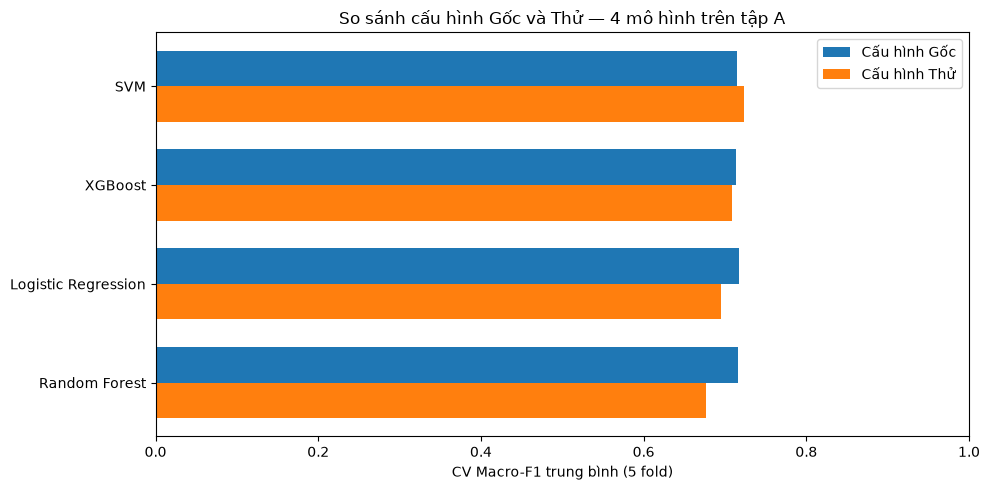

Đã lưu kết quả tại: C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-18_ThuThamSo_4MoHinh_TapA_Khoi
 - ket_qua.xlsx
 - ket_qua_tong_hop.csv
 - diem_tung_fold.csv
 - so_sanh_goc_va_thu.csv
 - so_sanh_macro_f1.png


In [4]:
output_dir.mkdir(parents=True, exist_ok=True)

excel_path = output_dir / "ket_qua.xlsx"
summary_path = output_dir / "ket_qua_tong_hop.csv"
fold_path = output_dir / "diem_tung_fold.csv"
comparison_path = output_dir / "so_sanh_goc_va_thu.csv"
image_path = output_dir / "so_sanh_macro_f1.png"

run_info = pd.DataFrame([{
    "Người chạy": "Nguyễn Hoàng Khởi",
    "Ngày thực nghiệm": "18/11/2026",
    "Tập đặc trưng": "A",
    "Dữ liệu": "data/processed/development.csv",
    "Số mẫu": len(y),
    "Số đặc trưng": X_a.shape[1],
    "Kiểm định chéo": "StratifiedKFold",
    "Số fold": N_FOLDS,
    "Shuffle": True,
    "Random state": SEED,
    "Chỉ số chính": "CV Macro-F1 trung bình",
    "scikit-learn": sklearn.__version__,
}])

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    results.to_excel(writer, sheet_name="Tong hop", index=False)
    comparison.to_excel(writer, sheet_name="So sanh goc va thu", index=False)
    fold_results.to_excel(writer, sheet_name="Diem tung fold", index=False)
    config_table.to_excel(writer, sheet_name="Cau hinh mo hinh", index=False)
    run_info.to_excel(writer, sheet_name="Thong tin", index=False)

results.to_csv(summary_path, index=False)
fold_results.to_csv(fold_path, index=False)
comparison.to_csv(comparison_path, index=False)

plot_data = comparison.set_index("Mô hình")
fig, ax = plt.subplots(figsize=(10, 5))
y_positions = range(len(plot_data))
bar_height = 0.36
ax.barh(
    [position - bar_height / 2 for position in y_positions],
    plot_data["CV Macro-F1 Gốc"],
    height=bar_height,
    label="Cấu hình Gốc",
)
ax.barh(
    [position + bar_height / 2 for position in y_positions],
    plot_data["CV Macro-F1 Thử"],
    height=bar_height,
    label="Cấu hình Thử",
)
ax.set_yticks(list(y_positions), plot_data.index)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("CV Macro-F1 trung bình (5 fold)")
ax.set_title("So sánh cấu hình Gốc và Thử — 4 mô hình trên tập A")
ax.legend()
fig.tight_layout()
fig.savefig(image_path, dpi=180, bbox_inches="tight")
plt.show()

print("Đã lưu kết quả tại:", output_dir.resolve())
for path in (excel_path, summary_path, fold_path, comparison_path, image_path):
    print(" -", path.name)

## 5. Nhận xét
Sau khi chạy toàn bộ notebook, dựa vào bảng So sánh cấu hình Gốc và cấu hình Thử để ghi nhận:
- Mô hình có CV Macro-F1 cao nhất trong bốn cấu hình Thử.
- Với từng mô hình, cấu hình Thử tăng hay giảm so với cấu hình Gốc.
- Mức chênh lệch CV Macro-F1 và tham số đã thay đổi.
- Chỉ kết luận trong phạm vi các cấu hình được thử trên tập A; không dùng điểm của một fold riêng lẻ để kết luận.